# СИЛАНТ · 06. Долгосрочный прогноз: 8 кварталов, три сценария, расширенные интервалы

Сценарии и модель — как на этапе 05 (Комбинация: Наивный + ETS + двухфакторная ARX со ставкой и инвестициями). Новое здесь — **явное послойное расширение интервалов** для горизонта 5–8 кварталов, который невозможно проверить на истории: при 13 точках ни одна обучающая выборка не даёт фактов на 8 кварталов вперёд.

| Слой | Что добавляется | Как задан |
|---|---|---|
| **L1. Статистический** | бутстреп остатков, неопределённость сезонности, половина SE коэффициентов; ширина × 1,5 | калибровка этапа 04 (проверена на h = 1–4) |
| **L2. + непроверенный горизонт** | множитель ширины k_h растёт с горизонтом | на rolling-origin для каждого h = 1–4 найден минимальный k, дающий 80 %-ное покрытие; линейный тренд k(h) продлён на h = 5–8 |
| **L3. + неопределённость факторов** | ставка и инвестиции в каждой траектории отклоняются от сценарной линии (случайное блуждание); полная SE коэффициентов | ставка: σ = 0,5·√j п. п., где j — кварталов после последней известной ставки (≈ ±1 п. п. к концу 2027 — ширина коридора ЦБ); инвестиции: σ = 2·√(h−1) п. п., не больше 5 (пересмотр прогноза Минэкономразвития на 2026 с −1,5 % до −5,4 % за 4 месяца) |
| **L4. + структурная** | вместо усреднения моделей каждая траектория целиком берётся из одной модели (Наивный / ETS / ARX, p = ⅓) — «восстановление ДВС будет или нет» | смесь моделей; на h = 1–4 даёт покрытие 87 % / 99 % для 80 % / 95 % интервалов (т. е. с запасом) |

**Центральный прогноз** — медиана слоя L1, то есть проверенной модели этапа 05 (совпадает с ним). Медианы расширенных слоёв не используются: расширение ширины лог-распределения сдвигает медиану суммы за 4 квартала вверх, и это статистический эффект, а не информация о рынке. Интервалы слоёв вложены друг в друга и показывают, **откуда берётся неопределённость**.

---
**Место в пайплайне:** шаг 6 из 6. Предыдущий: 05 — сценарии. Следующий: — (итоги собирает `update.py`: `reports/summary.html`, Excel). Запуск всех шагов: `python update.py`.

**Вход:** `data/processed/market_long.csv`, `macro_quarterly_wide.csv`, `interval_calibration.json`; `data/external/manual/scenarios.csv`.

**Выход:** `data/processed/long_forecast_*.csv`; графики `50–53_*.png`.

**Содержание:** 0. Настройка · 1. Слой L2: как ширина интервала должна расти с горизонтом · 2. Слой L3: разброс факторов вокруг сценарной траектории · 3. Расчёт: 3 сценария × 4 слоя · 4. Как расширяются интервалы: вклад каждого слоя · 5. Итоговые таблицы: сценарии × сегменты · 6. Доля электропогрузчиков на 8 кварталов · 7. Что всё-таки можно утверждать на 2-й год: вероятности (базовый сценарий, слой L3) · 8. Выводы

## 0. Настройка
Импорт библиотек, пути (относительно корня проекта), параметры и фиксированный seed для случайных чисел. Общие функции вынесены в модули `src/`, чтобы ноутбук содержал только логику анализа.

In [1]:
import sys
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from silant_data import load_market
from silant_ts import build_series
from silant_forecast import forecast_all, rolling_origin, share_draws

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
OUT = ROOT / "data/processed"
FIG = ROOT / "reports/figures"
COL = {"ДВС": "#eb6834", "Электро": "#2a78d6", "Рынок": "#52514e"}
SCOL = {"Консервативный": "#e34948", "Базовый": "#52514e", "Оптимистичный": "#1baf7a"}
SCN = ["Консервативный", "Базовый", "Оптимистичный"]
LAYERS = ["L1", "L2", "L3", "L4"]
LNAME = {
    "L1": "L1 статистический",
    "L2": "L2 + горизонт",
    "L3": "L3 + факторы",
    "L4": "L4 + структурный",
}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "font.size": 10,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "lines.linewidth": 2,
    }
)
thous = mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
pctf = mt.PercentFormatter(1.0, decimals=0)


def qlab(p):
    p = pd.Period(p, freq="Q")
    return f"{('I', 'II', 'III', 'IV')[p.quarter - 1]} кв. {p.year}"


def fmt0(v):
    return f"{v:,.0f}".replace(",", " ")


SOURCE_NOTE = (
    "Источники: данные заказчика, Банк России, Росстат, Минэкономразвития России; расчёты автора."
)
UNITS = {"52_fan_long": "Продажи, шт.", "53_share_long": "Доля электропогрузчиков"}


def save(fig, name):
    # подпись оси Y (единицы) там, где её нет, и источник данных под рисунком
    unit = UNITS.get(name)
    if unit:
        for ax in fig.axes:
            if not ax.get_ylabel() and ax.get_label() != "<colorbar>":
                ax.set_ylabel(unit)
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, bottom - 0.02, SOURCE_NOTE, fontsize=8, color="#555555", ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


S = build_series(load_market(ROOT / "data/raw/silant_forklift_market.xlsx")[0])
W = pd.read_csv(OUT / "macro_quarterly_wide.csv", index_col=0)
W.index = pd.PeriodIndex(W.index, freq="Q")
INFL = json.loads((OUT / "interval_calibration.json").read_text(encoding="utf-8"))
K0 = INFL["Комбинация"]
LAST = S.index.max()
H = 8
FUT = pd.period_range(LAST + 1, periods=H, freq="Q")
Y1, Y2 = FUT[:4], FUT[4:]
P1, P2 = f"{qlab(Y1[0])}–{qlab(Y1[-1])}", f"{qlab(Y2[0])}–{qlab(Y2[-1])}"
KEY = ["Рынок", "ДВС", "Электро"]
kr_fact = W["key_rate_avg"].dropna()
inv_fact = W["invest_fc_yoy"].dropna()

from silant_scenarios import scenario_paths

paths, PASS, SC_NOTES = scenario_paths(W, ROOT, LAST, H=H)
for n_ in SC_NOTES:
    print("⚠️", n_)
KR_BT = paths["Базовый"]["kr"]
print("Горизонт:", P1, "+", P2, "| базовая калибровка k =", K0)

Горизонт: II кв. 2026–I кв. 2027 + II кв. 2027–I кв. 2028 | базовая калибровка k = 1.5


## 1. Слой L2: как ширина интервала должна расти с горизонтом

,1.000000,1.250000,1.500000,1.750000,2.000000,2.250000,2.500000,3.000000,3.500000
h,,,,,,,,,
1,76%,82%,87%,89%,91%,93%,96%,100%,100%
2,64%,80%,84%,91%,93%,95%,95%,98%,100%
3,64%,73%,82%,88%,97%,100%,100%,100%,100%
4,59%,73%,77%,82%,100%,100%,100%,100%,100%


Минимальный k для 80 %-ного покрытия по h=1..4: {1: 1.25, 2: 1.5, 3: 1.5, 4: 1.75} → тренд k(h) = 1.12 + 0.15·h
k_h, используемый для h=1..8: [1.5  1.5  1.57 1.72 1.87 2.02 2.17 2.32] | сверх базового × [1.   1.   1.05 1.15 1.25 1.35 1.45 1.55]


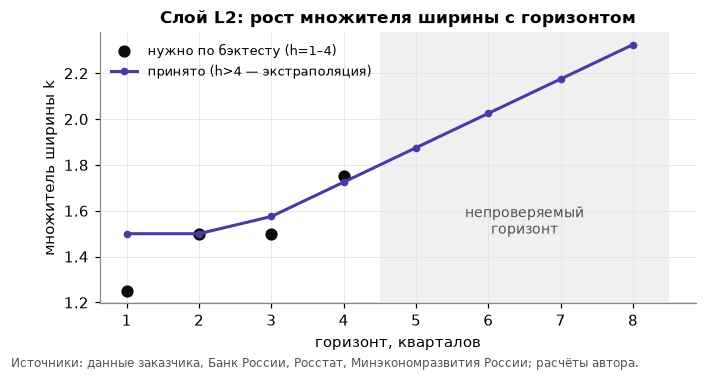

In [2]:
grid = [1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0, 3.5]
cov = {}
for k in grid:
    b = rolling_origin(
        S,
        KR_BT,
        pd.Period("2024Q4", freq="Q"),
        LAST - 1,
        H=4,
        n_sim=500,
        seed=SEED,
        infl={"Комбинация": k},
    )
    d = b[
        (b.src == "rec")
        & (b.model == "Комбинация")
        & (b.node != "Доля электро")
        & ~b.node.str.contains("5,5")
    ]
    cov[k] = d.groupby("h").in80.mean()
cov = pd.DataFrame(cov)
k_need = cov.apply(lambda r: next((k for k in grid if r[k] >= 0.8), grid[-1]), axis=1)
slope, icpt = np.polyfit(k_need.index.to_numpy(), k_need.to_numpy(), 1)
hs = np.arange(1, H + 1)
k_h = np.maximum(K0, icpt + slope * hs)
HORIZON_INFL = k_h / K0
display(
    cov.style.format("{:.0%}").set_caption(
        "Покрытие 80 %-ного интервала комбинации при разных множителях k, по горизонту"
    )
)
print(
    f"Минимальный k для 80 %-ного покрытия по h=1..4: {k_need.to_dict()} → тренд k(h) = {icpt:.2f} + {slope:.2f}·h"
)
print(
    "k_h, используемый для h=1..8:",
    np.round(k_h, 2),
    "| сверх базового ×",
    np.round(HORIZON_INFL, 2),
)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(k_need.index, k_need, "o", color="#0b0b0b", ms=7, label="нужно по бэктесту (h=1–4)")
ax.plot(hs, k_h, color="#4a3aa7", marker="o", ms=4, label="принято (h>4 — экстраполяция)")
ax.axvspan(4.5, 8.5, color="#8a8984", alpha=0.12, lw=0)
ax.text(6.5, k_h.min(), "непроверяемый\nгоризонт", ha="center", fontsize=9, color="#52514e")
ax.set_xlabel("горизонт, кварталов")
ax.set_ylabel("множитель ширины k")
ax.legend(frameon=False, fontsize=8.5)
ax.set_title("Слой L2: рост множителя ширины с горизонтом")
save(fig, "50_horizon_k")

## 2. Слой L3: разброс факторов вокруг сценарной траектории

In [3]:
kr_last_known = kr_fact.index.max()
j = np.array(
    [max(0, (q - 2 - kr_last_known).n) for q in FUT]
)  # кварталов после последней известной ставки
SD_KR = np.minimum(0.5 * np.sqrt(j), 1.5)
inv_last_known = inv_fact.index.max()
jj = np.array([max(0, (q - inv_last_known).n) for q in FUT])
SD_INV = np.minimum(2.0 * np.sqrt(jj), 5.0)
FACTOR_SD = {"kr": SD_KR, "inv": SD_INV}
pd.DataFrame(
    {
        "квартал прогноза": [qlab(q) for q in FUT],
        "ставка берётся за": [qlab(q - 2) for q in FUT],
        "σ ставки, п.п.": SD_KR.round(2),
        "σ инвестиций, п.п.": SD_INV.round(2),
    }
).set_index("квартал прогноза")

,ставка берётся за,"σ ставки, п.п.","σ инвестиций, п.п."
квартал прогноза,,,
II кв. 2026,IV кв. 2025,0.00,0.00
III кв. 2026,I кв. 2026,0.00,2.00
IV кв. 2026,II кв. 2026,0.00,2.83
I кв. 2027,III кв. 2026,0.00,3.46
II кв. 2027,IV кв. 2026,0.50,4.00
III кв. 2027,I кв. 2027,0.71,4.47
IV кв. 2027,II кв. 2027,0.87,4.90
I кв. 2028,III кв. 2027,1.00,5.00


## 3. Расчёт: 3 сценария × 4 слоя

In [4]:
def run(s, layer):
    kw = dict(
        S=S,
        kr=paths[s]["kr"],
        origin=LAST,
        H=H,
        n_sim=4000,
        seed=SEED,
        infl=INFL,
        inv=paths[s]["inv"],
        kr_pass=PASS[s],
    )
    if layer in ("L2", "L3", "L4"):
        kw["horizon_infl"] = HORIZON_INFL
    if layer in ("L3", "L4"):
        kw.update(factor_sd=FACTOR_SD, full_param_se=True)
    if layer == "L4":
        kw["mixture"] = True
    f = forecast_all(**kw)
    return f["rec"]["Смесь" if layer == "L4" else "Комбинация"], f


SIMS, FC = {}, {}
for s in SCN:
    for L in LAYERS:
        SIMS[(s, L)], FC[(s, L)] = run(s, L)
nodes = FC[("Базовый", "L1")]["nodes"]
bottom = FC[("Базовый", "L1")]["bottom"]
order = (
    KEY
    + [b for b in bottom if b.startswith("ДВС")]
    + [b for b in bottom if b.startswith("Электро")]
)

rows = []
for (s, L), sims in SIMS.items():
    for n in nodes:
        for h, q in enumerate(FUT):
            v = sims[n][:, h]
            rows.append(
                {
                    "сценарий": s,
                    "слой": L,
                    "ряд": n,
                    "квартал": str(q),
                    "h": h + 1,
                    "P2.5": np.quantile(v, 0.025),
                    "P10": np.quantile(v, 0.1),
                    "P50": np.median(v),
                    "P90": np.quantile(v, 0.9),
                    "P97.5": np.quantile(v, 0.975),
                }
            )
Q = pd.DataFrame(rows)
Q.to_csv(OUT / "long_forecast_quarterly_layers.csv", index=False, encoding="utf-8-sig")
rows = []
for (s, L), sims in SIMS.items():
    for n in nodes:
        for per, qs_ in [(P1, Y1), (P2, Y2)]:
            idx = [list(FUT).index(q) for q in qs_]
            v = sims[n][:, idx].sum(1)
            rows.append(
                {
                    "сценарий": s,
                    "слой": L,
                    "ряд": n,
                    "период": per,
                    "P2.5": np.quantile(v, 0.025),
                    "P10": np.quantile(v, 0.1),
                    "P50": np.median(v),
                    "P90": np.quantile(v, 0.9),
                    "P97.5": np.quantile(v, 0.975),
                }
            )
T = pd.DataFrame(rows)
T.to_csv(OUT / "long_forecast_totals_layers.csv", index=False, encoding="utf-8-sig")
print("Сохранено:", len(Q), "строк поквартально и", len(T), "строк по годам")

Сохранено: 1248 строк поквартально и 312 строк по годам


## 4. Как расширяются интервалы: вклад каждого слоя

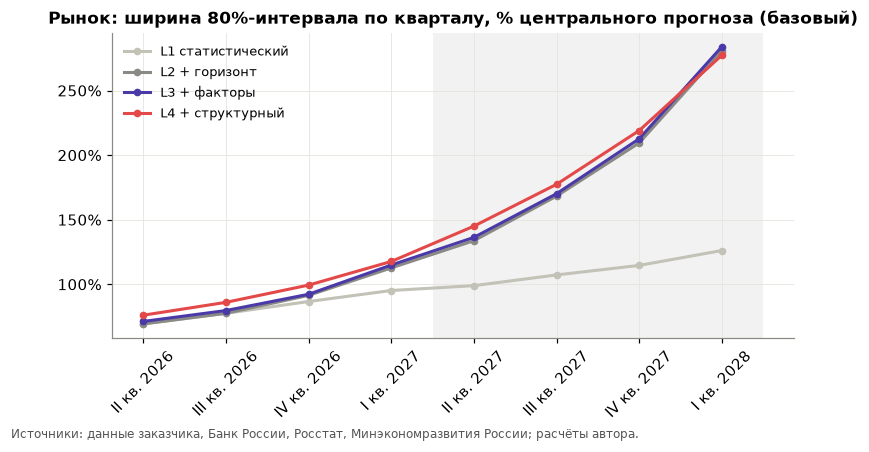

In [5]:
wd = T[(T["сценарий"] == "Базовый") & T["ряд"].isin(KEY)].copy()
c1 = T[(T["сценарий"] == "Базовый") & (T["слой"] == "L1")].set_index(["ряд", "период"]).P50
wd["ширина 80 %, % медианы"] = (wd.P90 - wd.P10) / [
    c1[(r, p)] for r, p in zip(wd["ряд"], wd["период"])
]
piv = wd.pivot_table(
    index=["ряд", "период"], columns="слой", values="ширина 80 %, % медианы"
).reindex(KEY, level=0)[LAYERS]
piv.columns = [LNAME[c] for c in piv.columns]
display(
    piv.style.format("{:.0%}").set_caption(
        "Ширина 80 %-ного интервала суммы за 4 квартала, в % от медианы (базовый сценарий)"
    )
)

wq = Q[(Q["сценарий"] == "Базовый") & (Q["ряд"] == "Рынок")].copy()
q1 = wq[wq["слой"] == "L1"].set_index("h").P50
wq["w"] = (wq.P90 - wq.P10) / wq.h.map(q1)
fig, ax = plt.subplots(figsize=(8, 3.6))
lc = {"L1": "#c3c2b7", "L2": "#8a8984", "L3": "#4a3aa7", "L4": "#e34948"}
for L in LAYERS:
    d = wq[wq["слой"] == L]
    ax.plot(d.h, d.w, marker="o", ms=4, color=lc[L], label=LNAME[L])
ax.axvspan(4.5, 8.5, color="#8a8984", alpha=0.1, lw=0)
ax.set_xticks(hs, [qlab(q) for q in FUT], rotation=45)
ax.yaxis.set_major_formatter(pctf)
ax.set_title("Рынок: ширина 80%-интервала по кварталу, % центрального прогноза (базовый)")
ax.legend(frameon=False, fontsize=8.5)
save(fig, "51_width_by_layer")

Веерные графики на 8 кварталов: вложенные интервалы слоёв L1–L4 и медианы трёх сценариев.

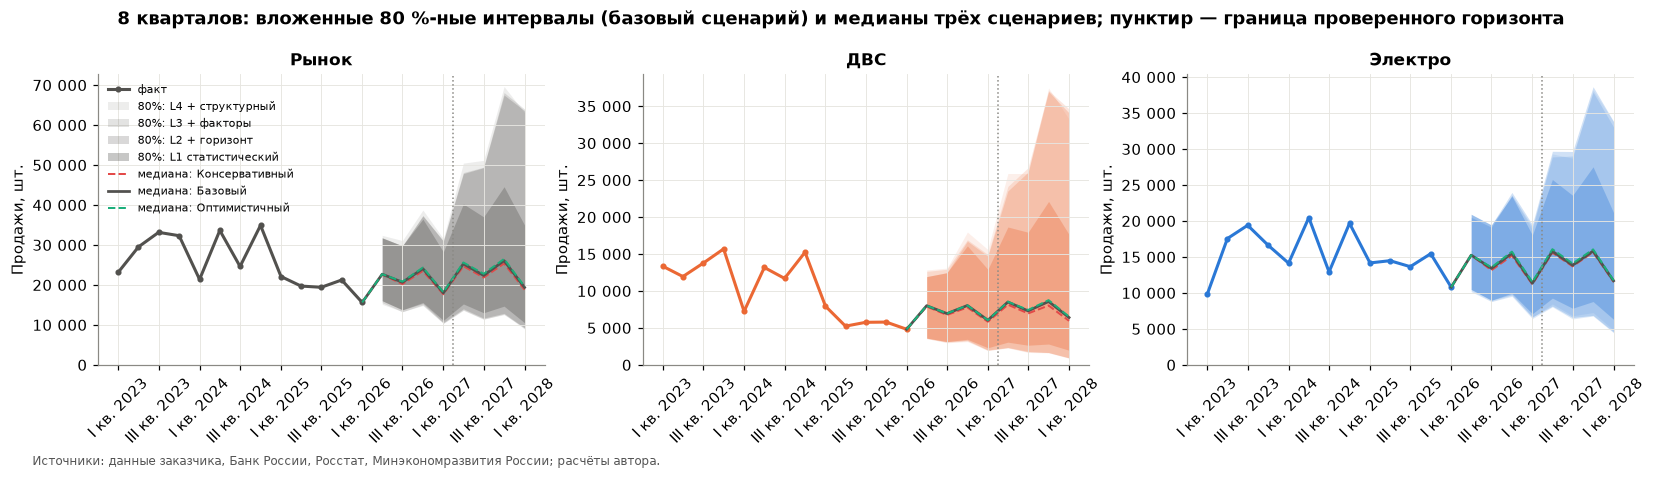

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
hist = S.index.to_timestamp()
x = FUT.to_timestamp()
alpha = {"L4": 0.10, "L3": 0.16, "L2": 0.22, "L1": 0.32}
for ax, n in zip(axes, KEY):
    ax.plot(hist, S[n], color=COL[n], marker="o", ms=3, label="факт")
    for L in ["L4", "L3", "L2", "L1"]:
        d = Q[(Q["сценарий"] == "Базовый") & (Q["слой"] == L) & (Q["ряд"] == n)]
        ax.fill_between(
            x, d.P10, d.P90, color=COL[n], alpha=alpha[L], lw=0, label=f"80%: {LNAME[L]}"
        )
    for s in SCN:
        d = Q[(Q["сценарий"] == s) & (Q["слой"] == "L1") & (Q["ряд"] == n)]
        ax.plot(
            [hist[-1]] + list(x),
            [S[n].iloc[-1]] + list(d.P50),
            color=SCOL[s],
            lw=1.8 if s == "Базовый" else 1.3,
            ls="-" if s == "Базовый" else "--",
            label=f"медиана: {s}",
        )
    ax.axvline(FUT[4].to_timestamp() - pd.Timedelta(days=45), color="#8a8984", ls=":", lw=1)
    ax.set_title(n)
    ax.yaxis.set_major_formatter(thous)
    ax.set_ylim(bottom=0)
    t = list(S.index[::2]) + list(FUT[1::2])
    ax.set_xticks([q.to_timestamp() for q in t], [qlab(q) for q in t], rotation=45)
axes[0].legend(frameon=False, fontsize=7, loc="upper left", ncol=1)
fig.suptitle(
    "8 кварталов: вложенные 80 %-ные интервалы (базовый сценарий) и медианы трёх сценариев; пунктир — граница проверенного горизонта",
    fontweight="bold",
)
fig.tight_layout()
save(fig, "52_fan_long")

## 5. Итоговые таблицы: сценарии × сегменты

In [7]:
out = {}
for per in [P1, P2]:
    for s in SCN:
        c = (
            T[(T["сценарий"] == s) & (T["слой"] == "L1") & (T["период"] == per)]
            .set_index("ряд")
            .loc[order]
        )
        d = (
            T[(T["сценарий"] == s) & (T["слой"] == "L3") & (T["период"] == per)]
            .set_index("ряд")
            .loc[order]
        )
        out[(per, s)] = [f"{fmt0(a)} ({fmt0(b)}–{fmt0(e)})" for a, b, e in zip(c.P50, d.P10, d.P90)]

tab = pd.DataFrame(out, index=order)
tab.insert(0, ("факт", "последние 4 кв."), S.iloc[-4:].sum().reindex(order).map(fmt0))
tab.columns = pd.MultiIndex.from_tuples(tab.columns)
tab.to_csv(OUT / "long_forecast_table_L3.csv", encoding="utf-8-sig")
tab.style.set_caption(
    "Центральный прогноз (медиана L1) и 80 %-ный интервал слоя L3 (статистика + горизонт + факторы) за 4 квартала, шт."
)

**Вывод по таблице выше.** В первом году рынок 85,5 / 87,2 / 87,8 тыс. шт. (консервативный / базовый / оптимистичный), во втором 92,8 / 95,2 / 96,8. Разница между сценариями — единицы процентов, а 80 %-ный интервал слоя L3 базового сценария во втором году (53,5–216,1 тыс.) примерно в 2,7 раза шире, чем в первом (61,1–120,6). Второй год можно использовать как диапазон, а не как точечный прогноз.

Следующая таблица: 80 %-ный интервал второго года по слою L4, где каждая траектория целиком берётся из одной модели (наивной, ETS или ARX), то есть добавлена неопределённость «восстановятся ли ДВС».

In [8]:
d4 = T[(T["слой"] == "L4") & (T["период"] == P2)]
full = d4.pivot_table(index="ряд", columns="сценарий", values=["P10", "P90"]).reindex(order)
full = pd.DataFrame(
    {s: [f"{fmt0(a)}–{fmt0(b)}" for a, b in zip(full[("P10", s)], full[("P90", s)])] for s in SCN},
    index=order,
)
full.style.set_caption(
    f"{P2}: 80 %-ный интервал с учётом структурной неопределённости (слой L4), шт."
)

,Консервативный,Базовый,Оптимистичный
Рынок,51 171–222 496,54 666–221 385,55 762–222 496
ДВС,8 104–119 054,8 527–117 012,8 551–117 570
Электро,31 324–125 577,32 299–125 700,32 538–126 454
"ДВС 1–1,8 т",968–32 771,998–32 213,1 000–32 644
"ДВС 2–2,5 т",1 080–27 394,1 113–26 832,1 113–26 953
"ДВС 3–3,5 т",1 509–49 698,1 532–50 128,1 532–50 430
"ДВС 3,8–5 т",433–6 516,437–6 678,439–6 793
"ДВС 5,5 т+",386–3 261,428–3 243,433–3 237
"Электро 1–1,8 т",9 441–42 496,9 458–43 207,9 458–43 590
"Электро 2–2,5 т",5 483–33 918,5 521–33 984,5 539–34 330


## 6. Доля электропогрузчиков на 8 кварталов

In [9]:
rows = []
for s in SCN:
    for L in ["L1", "L3", "L4"]:
        sims = SIMS[(s, L)]
        for per, qs_ in [(P1, Y1), (P2, Y2)]:
            idx = [list(FUT).index(q) for q in qs_]
            v = sims["Электро"][:, idx].sum(1) / sims["Рынок"][:, idx].sum(1)
            rows.append(
                {
                    "сценарий": s,
                    "слой": L,
                    "период": per,
                    "медиана": np.median(v),
                    "P10": np.quantile(v, 0.1),
                    "P90": np.quantile(v, 0.9),
                }
            )
SH = pd.DataFrame(rows)
SH.to_csv(OUT / "long_forecast_e_share.csv", index=False, encoding="utf-8-sig")
print(f"Факт за последние 4 кв.: {S['Электро'].iloc[-4:].sum() / S['Рынок'].iloc[-4:].sum():.1%}")
SH.pivot_table(
    index=["сценарий", "слой"], columns="период", values=["медиана", "P10", "P90"]
).reindex(SCN, level=0).style.format("{:.0%}")

Факт за последние 4 кв.: 71.6%


Доля электропогрузчиков на 8 кварталов на графике.

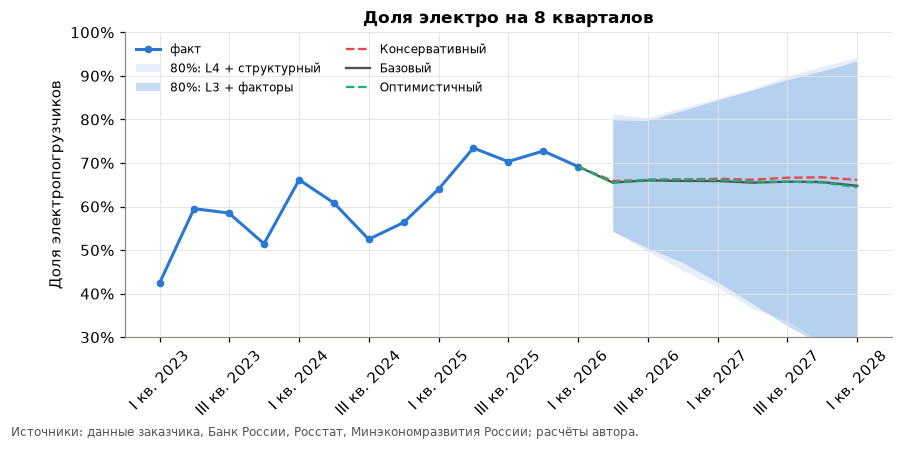

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
sh = S["Электро"] / S["Рынок"]
ax.plot(S.index.to_timestamp(), sh, color=COL["Электро"], marker="o", ms=4, label="факт")
for L, a in [("L4", 0.12), ("L3", 0.25)]:
    v = share_draws(SIMS[("Базовый", L)])
    ax.fill_between(
        FUT.to_timestamp(),
        np.quantile(v, 0.1, 0),
        np.quantile(v, 0.9, 0),
        color=COL["Электро"],
        alpha=a,
        lw=0,
        label=f"80%: {LNAME[L]}",
    )
for s in SCN:
    v = share_draws(SIMS[(s, "L1")])
    ax.plot(
        [S.index[-1].to_timestamp()] + list(FUT.to_timestamp()),
        [sh.iloc[-1]] + list(np.median(v, 0)),
        color=SCOL[s],
        ls="-" if s == "Базовый" else "--",
        lw=1.5,
        label=s,
    )
ax.yaxis.set_major_formatter(pctf)
ax.set_ylim(0.3, 1)
t = list(S.index[::2]) + list(FUT[1::2])
ax.set_xticks([q.to_timestamp() for q in t], [qlab(q) for q in t], rotation=45)
ax.set_title("Доля электро на 8 кварталов")
ax.legend(frameon=False, fontsize=8, ncol=2)
save(fig, "53_share_long")

## 7. Что всё-таки можно утверждать на 2-й год: вероятности (базовый сценарий, слой L3)

In [11]:
sims = SIMS[("Базовый", "L3")]
i1 = [list(FUT).index(q) for q in Y1]
i2 = [list(FUT).index(q) for q in Y2]
l4 = S.iloc[-4:].sum()


def P(x):
    return f"{x.mean():.0%}"


probs = {
    f"Рынок {P2} больше последних 4 кв. факта": P(sims["Рынок"][:, i2].sum(1) > l4["Рынок"]),
    f"ДВС {P2} больше последних 4 кв. факта": P(sims["ДВС"][:, i2].sum(1) > l4["ДВС"]),
    f"Электро {P2} больше последних 4 кв. факта": P(sims["Электро"][:, i2].sum(1) > l4["Электро"]),
    f"Электро 1–2,5 т {P2} больше последних 4 кв.": P(
        (sims["Электро 1–1,8 т"] + sims["Электро 2–2,5 т"])[:, i2].sum(1)
        > l4["Электро 1–1,8 т"] + l4["Электро 2–2,5 т"]
    ),
    f"Электропогрузчиков продано больше, чем ДВС ({P2})": P(
        sims["Электро"][:, i2].sum(1) > sims["ДВС"][:, i2].sum(1)
    ),
    f"Доля электро {P2} выше 60 %": P(
        sims["Электро"][:, i2].sum(1) / sims["Рынок"][:, i2].sum(1) > 0.6
    ),
    f"ДВС {P2} вернётся к уровню 2024 г. (≥ 47 тыс.)": P(sims["ДВС"][:, i2].sum(1) >= 47000),
    f"Рынок {P2} вернётся к уровню 2024 г. (≥ 114 тыс.)": P(sims["Рынок"][:, i2].sum(1) >= 114000),
}
pd.Series(probs, name="вероятность").to_frame()

,вероятность
Рынок II кв. 2027–I кв. 2028 больше последних 4 кв. факта,74%
ДВС II кв. 2027–I кв. 2028 больше последних 4 кв. факта,69%
Электро II кв. 2027–I кв. 2028 больше последних 4 кв. факта,57%
"Электро 1–2,5 т II кв. 2027–I кв. 2028 больше последних 4 кв.",51%
"Электропогрузчиков продано больше, чем ДВС (II кв. 2027–I кв. 2028)",71%
Доля электро II кв. 2027–I кв. 2028 выше 60 %,56%
ДВС II кв. 2027–I кв. 2028 вернётся к уровню 2024 г. (≥ 47 тыс.),39%
Рынок II кв. 2027–I кв. 2028 вернётся к уровню 2024 г. (≥ 114 тыс.),46%


### Проверка актуальности выводов
Текст выводов ниже написан по данным до I кв. 2026 г. Если в файле появился новый квартал, эта ячейка выведет предупреждение; таблицы и графики выше при этом пересчитываются автоматически.

In [12]:
from IPython.display import Markdown, display
from silant_data import load_market as _lm
_last = str(_lm(ROOT / 'data/raw/silant_forklift_market.xlsx')[0].quarter.max())
if _last != "2026Q1":
    display(Markdown(f"> ⚠️ **Текст выводов ниже написан по данным до 2026Q1**, а в файле данные уже до **{_last}**. "
                     "Все таблицы и графики выше пересчитаны автоматически; конкретные цифры в тексте могли устареть — "
                     "актуальные значения см. в таблицах выше, в `reports/summary.html` и `reports/silant_forecast.xlsx`."))
else:
    print("Текст выводов соответствует текущим данным (до 2026Q1).")

Текст выводов соответствует текущим данным (до 2026Q1).


## 8. Выводы

### 8.1 Как и почему расширены интервалы
- **Слой L2 (горизонт) — главный источник расширения.** На бэктесте нужный множитель ширины растёт с горизонтом: 1,25 → 1,5 → 1,5 → 1,75 для h = 1–4 (тренд k(h) = 1,12 + 0,15·h). Продлённый на 5–8 кварталов, он даёт k = 1,87…2,32 — в 1,25–1,55 раза шире проверенной калибровки. Это экстраполяция по 4 точкам, а не проверенный факт.
- **Слой L3 (факторы) почти ничего не добавляет** (+1–8 п. п. ширины). Ставка на первый год уже известна, а макроэффект входит в комбинацию с весом ⅓.
- **Слой L4 (структурный: восстановление ДВС или нет) заметен только по ДВС в первом году:** ширина 127 % → 143 %. Во втором году он тонет в неопределённости горизонта.

Ширина 80 %-ный интервала суммы за 4 квартала, % центрального прогноза (базовый сценарий):

| | L1 | L2 | L3 | L4 |
|---|---|---|---|---|
| Рынок, II кв. 2026 — I кв. 2027 | 61 % | 66 % | 68 % | 76 % |
| Рынок, II кв. 2027 — I кв. 2028 | 95 % | 170 % | 171 % | 175 % |
| ДВС, II кв. 2027 — I кв. 2028 | 183 % | 322 % | 330 % | 333 % |
| Электро, II кв. 2027 — I кв. 2028 | 99 % | 162 % | 160 % | 160 % |

### 8.2 Прогноз на 8 кварталов (центр — медиана L1; 80 %-ный интервал — слой L3)
| | Факт, последние 4 кв. | II кв. 2026 — I кв. 2027: база (конс. / опт.) | II кв. 2027 — I кв. 2028: база (конс. / опт.) |
|---|---|---|---|
| **Рынок** | 76,0 тыс. | **87,2** (85,5 / 87,8); 61–121 | **95,2** (92,8 / 96,8); 54–216 |
| ДВС | 21,6 тыс. | **29,8** (29,1 / 29,9); 15–53 | **32,6** (30,8 / 33,1); 9–116 |
| Электро | 54,4 тыс. | **56,4** (55,6 / 57,0); 39–77 | **58,3** (57,7 / 59,1); 30–123 |
| Электро 1–1,8 т | 24,6 тыс. | 25,8; 18–35 | 25,4; 9–47 |
| Электро 2–2,5 т | 14,3 тыс. | 16,2; 10–23 | 16,0; 5–37 |
| ДВС 3–3,5 т | 8,4 тыс. | 11,6; 5–23 | 12,0; 2–52 |
| Доля электро | 71,6 % | 65 % (51–78 %) | 65 % (32–88 %) |

### 8.3 Что это значит
1. **Второй год количественно почти не определён.** 80 %-ный интервал рынка — от 54 до 216 тыс. шт. Верхние границы для ДВС (116 тыс.) и рынка (216 тыс.) выше всего, что наблюдалось (максимум — 2023 год: ДВС 54,7 тыс., рынок 118 тыс.). Мультипликативное расширение случайного блуждания завышает правый хвост. Для планирования разумно считать исторический максимум потолком, а в работу брать нижнюю половину интервала.
2. **Сценарии по-прежнему различаются меньше, чем неопределённость внутри каждого из них:** 2–5 % против 170 %. Во втором году это ещё заметнее, чем в первом.
3. **Устойчивые вероятностные утверждения на II кв. 2027 — I кв. 2028** (базовый сценарий, слой L3; это верхние оценки — модель на истории завышала рынок на 34 %):
   - рынок превысит факт последних 4 кварталов — 74 %;
   - продажи ДВС превысят факт — 69 %, электропогрузчиков — 57 %;
   - электропогрузчиков будет продано больше, чем погрузчиков с ДВС, — 71 %;
   - ДВС вернётся к уровню 2024 года (≥ 47 тыс.) — 39 %;
   - рынок вернётся к уровню 2024 года (≥ 114 тыс.) — 46 %.
4. **Электро 1–2,5 т:** в первом году интервал узкий (±35 %), во втором — шансы «больше или меньше последних 4 кварталов» 51 на 49. С учётом спада −26…−28 % г/г и завышения модели на истории (этап 04, раздел 5.4) выпуск держать на уровне текущего спроса и пересматривать ежеквартально.

### 8.4 Как пользоваться прогнозом на 8 кварталов
- **Производственный план — на 4 квартала** (проверенный горизонт, слой L1–L2).
- **Кварталы 5–8 — для стратегических решений** (модельный ряд, локализация, мощности), и только в терминах вероятностей и порогов, а не точечных значений.
- **Каждый новый квартал фактических данных** сдвигает горизонт и заменяет самый неопределённый квартал проверенным. Пересчёт: `python update.py`. Множитель k(h) пересчитывается на новых данных автоматически; параметры разброса факторов (σ) задаются в первых ячейках раздела 2.